# Assignment 4 Logistic Regression

Predict AL/RF and the three hierarchical clusters from Assignment 3 using logistic regression.
Run the cells in order to reproduce the analysis.


In [1]:
from pathlib import Path
import json
import hashlib
import platform
import time
import warnings
import numpy as np
import pandas as pd
import scipy
from scipy.special import expit
import sklearn
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score, roc_curve, confusion_matrix
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
ROOT = Path.cwd().resolve()
OUT = ROOT / "results" / "assignment4" / "logistic_regression"
GENE_COUNTS = (10, 100, 1000, 5000, 10000)
SEED = 42
N_FOLDS = 5
METHOD = "logistic_L1"
TARGETS = ("feeding_group", "hierarchical_cluster")
PARAMETERS = dict(C=1.0, penalty="l1", solver="liblinear", class_weight="balanced",
                  max_iter=3000, tol=1e-4, random_state=SEED)

from IPython.display import display, Image, Markdown

NOTEBOOK_PATH = ROOT / "assignment4_logistic.ipynb"
if not NOTEBOOK_PATH.is_file() or not (ROOT / "Data/SRP064298/gene_data.tsv").is_file():
    raise FileNotFoundError("Open this notebook from the project folder containing Data.")


def notebook_code_hash(path=NOTEBOOK_PATH):
    notebook = json.loads(Path(path).read_text(encoding="utf-8"))
    code = "\n\n".join("".join(cell["source"]) for cell in notebook["cells"]
                         if cell["cell_type"] == "code")
    return hashlib.sha256(code.encode("utf-8")).hexdigest()


## Data

There are 546 WT sequencing runs: 367 AL and 179 RF. Cluster labels come from selected_clusters.csv.
The expression data were already normalized in Assignment 2.


In [2]:
def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def load_inputs(root=ROOT):
    root = Path(root)
    paths = dict(
        expression=root / "Data/SRP064298/gene_data.tsv",
        metadata=root / "Data/SRP064298/metadata_SRP064298.tsv",
        clusters=root / "results/assignment3/hierarchical/selected_clusters.csv",
        processing=root / "Data/aggregated_metadata.json",
    )
    for path in paths.values():
        if not path.is_file():
            raise FileNotFoundError(path)
    expression = pd.read_csv(paths["expression"], sep="\t")
    metadata = pd.read_csv(paths["metadata"], sep="\t").set_index("refinebio_accession_code")
    if metadata.index.has_duplicates or expression.columns[1:].has_duplicates:
        raise ValueError("Duplicate sequencing accession IDs.")
    if set(metadata.index) != set(expression.columns[1:]):
        raise ValueError("Expression and metadata accession sets differ.")
    metadata = metadata.loc[expression.columns[1:]]
    metadata = metadata.loc[
        metadata["refinebio_title"].str.startswith(("WT_AL_", "WT_RF_"), na=False)
    ].copy()
    metadata.index.name = "sample_id"
    metadata["feeding_group"] = metadata["refinebio_title"].str.split("_").str[1]
    metadata["title_group"] = metadata["refinebio_title"]
    if metadata["title_group"].isna().any():
        raise ValueError("Missing title used for grouped evaluation.")
    if metadata.groupby("title_group")["feeding_group"].nunique().max() != 1:
        raise ValueError("One title maps to conflicting feeding labels.")
    clusters = pd.read_csv(paths["clusters"], dtype={"sample_id": str, "cluster": str})
    if clusters["sample_id"].duplicated().any():
        raise ValueError("Duplicate selected-cluster sample IDs.")
    if set(clusters["sample_id"]) != set(metadata.index):
        raise ValueError("Selected hierarchical labels do not match the WT cohort.")
    metadata["hierarchical_cluster"] = clusters.set_index("sample_id")["cluster"].reindex(metadata.index)
    if set(metadata["feeding_group"]) != {"AL", "RF"}:
        raise ValueError("Expected exactly AL and RF.")
    if set(metadata["hierarchical_cluster"]) != {"1", "2", "3"}:
        raise ValueError("Expected the selected three-cluster solution.")
    X = expression.loc[:, metadata.index].to_numpy(dtype=float).T.copy()
    if not np.isfinite(X).all():
        raise ValueError("Expression contains missing or infinite values.")
    features = pd.DataFrame({
        "feature_id": ["gene_row_%05d" % i for i in range(len(expression))],
        "gene_symbol": expression["Gene"].fillna("").astype(str),
        "source_row": np.arange(len(expression)),
    })
    if features["gene_symbol"].eq("").any():
        raise ValueError("Empty gene symbols.")
    audit = {
        "n_runs": len(metadata),
        "n_distinct_titles": int(metadata["title_group"].nunique()),
        "n_gene_rows": len(features),
        "n_unique_symbols": int(features["gene_symbol"].nunique()),
        "additional_rows_with_repeated_symbols": int(features["gene_symbol"].duplicated().sum()),
        "feeding_group_counts": metadata["feeding_group"].value_counts().to_dict(),
        "selected_cluster_counts": metadata["hierarchical_cluster"].value_counts().to_dict(),
        "input_sha256": {key: sha256(path) for key, path in paths.items()},
    }
    return {"X": X, "metadata": metadata, "features": features, "audit": audit, "paths": paths}


In [3]:
data = load_inputs()
display(data["metadata"][["feeding_group", "hierarchical_cluster", "title_group"]].head())


,feeding_group,hierarchical_cluster,title_group
sample_id,,,
SRR2534402,AL,1,WT_AL_ZT00_A_RNA
SRR2534403,AL,1,WT_AL_ZT00_A_RNA
SRR2534404,AL,1,WT_AL_ZT00_A_RNA
SRR2534405,AL,1,WT_AL_ZT00_A_RNA
SRR2534406,AL,1,WT_AL_ZT00_A_RNA


## Gene selection

Each training fold selects genes with the highest expression variance.
Repeated gene symbols keep separate row IDs.


In [4]:
class MostVariableGenes(BaseEstimator, TransformerMixin):
    """Rank raw expression variance using only the samples passed to fit."""
    def __init__(self, n_genes=5000):
        self.n_genes = n_genes

    def fit(self, X, y=None):
        X = np.asarray(X)
        if X.ndim != 2 or len(X) < 2:
            raise ValueError("Expected at least two training observations.")
        self.n_features_in_ = X.shape[1]
        self.variances_ = X.var(axis=0, ddof=1)
        order = np.argsort(-self.variances_, kind="mergesort")
        order = order[self.variances_[order] > 0]
        if len(order) < self.n_genes:
            raise ValueError("Too few variable gene rows for the requested count.")
        self.selected_indices_ = order[:self.n_genes]
        return self

    def transform(self, X):
        X = np.asarray(X)
        if X.shape[1] != self.n_features_in_:
            raise ValueError("Gene columns differ from the training feature set.")
        return X[:, self.selected_indices_]


## Cross validation

We use five folds and keep runs with the same title together.
The same folds are used for both targets and all gene counts.


In [5]:
def make_splits(data, n_folds=N_FOLDS):
    meta = data["metadata"]
    splitter = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=SEED)
    splits = list(splitter.split(data["X"], meta["feeding_group"], groups=meta["title_group"]))
    assignments = np.full(len(meta), -1, dtype=int)
    audit = []
    for fold, (train, test) in enumerate(splits, 1):
        train_titles = set(meta.iloc[train]["title_group"])
        test_titles = set(meta.iloc[test]["title_group"])
        if train_titles & test_titles:
            raise ValueError("A repeated title crosses train and test.")
        if (assignments[test] != -1).any():
            raise ValueError("Duplicate out-of-fold predictions.")
        assignments[test] = fold
        record = dict(fold=fold, n_train_runs=len(train), n_test_runs=len(test),
                      n_train_titles=len(train_titles), n_test_titles=len(test_titles), title_overlap=0)
        for target in TARGETS:
            expected = set(meta[target])
            if set(meta.iloc[train][target]) != expected or set(meta.iloc[test][target]) != expected:
                raise ValueError("A fold is missing a target class; review grouped splits before fitting.")
            for label in sorted(expected):
                record["test_%s_%s" % (target, label)] = int((meta.iloc[test][target] == label).sum())
        audit.append(record)
    if (assignments < 0).any():
        raise ValueError("Some samples were never held out.")
    folds = meta[["title_group", "feeding_group", "hierarchical_cluster"]].copy()
    folds["fold"] = assignments
    if folds.groupby("title_group")["fold"].nunique().max() != 1:
        raise ValueError("A title has multiple fold assignments.")
    return splits, folds, pd.DataFrame(audit)


In [6]:
splits, folds, fold_audit = make_splits(data)
display(fold_audit[["fold", "n_train_runs", "n_test_runs", "title_overlap"]])


,fold,n_train_runs,n_test_runs,title_overlap
0,1,429,117,0
1,2,433,113,0
2,3,439,107,0
3,4,444,102,0
4,5,439,107,0


## Model

Logistic regression uses L1 regularization, C=1, balanced class weights and the liblinear solver.
L1 produces a smaller set of genes with nonzero coefficients.
For clusters, one-vs-rest lets us predict each of the three clusters using the same binary classifier.
Gene selection and scaling are fitted on training data only.


In [7]:
def make_model(n_genes, target):
    classifier = LogisticRegression(**PARAMETERS)
    if target == "hierarchical_cluster":
        classifier = OneVsRestClassifier(classifier, n_jobs=1)
    return Pipeline([
        ("genes", MostVariableGenes(n_genes)),
        ("scale", StandardScaler()),
        ("classifier", classifier),
    ])


def fit_checked(model, X, y):
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(X, y)
    failures = [str(item.message) for item in captured if issubclass(item.category, ConvergenceWarning)]
    if failures:
        raise RuntimeError("Logistic regression did not converge: " + "; ".join(failures))
    clf = model.named_steps["classifier"]
    estimators = clf.estimators_ if isinstance(clf, OneVsRestClassifier) else [clf]
    if any(np.max(est.n_iter_) >= PARAMETERS["max_iter"] for est in estimators):
        raise RuntimeError("An estimator reached its iteration limit.")
    return max(int(np.max(est.n_iter_)) for est in estimators)


def decision_scores(model, X):
    clf = model.named_steps["classifier"]
    classes = np.asarray(clf.classes_).astype(str)
    scores = model.decision_function(X)
    if np.ndim(scores) == 1:
        scores = np.column_stack([-scores, scores])
    predicted = classes[np.argmax(scores, axis=1)]
    return classes, scores, predicted


## Scores and gene coefficients

RF is the positive feeding label. Cluster AUC is the mean of the three one-vs-rest AUCs.
Nonzero coefficients define the gene signatures.


In [8]:
def measure(y, classes, scores, predicted, weights):
    y = np.asarray(y)
    indices = [1] if len(classes) == 2 else list(range(len(classes)))
    per_class = []
    for j in indices:
        binary = (y == classes[j]).astype(int)
        per_class.append({
            "positive_class": str(classes[j]),
            "auc": float(roc_auc_score(binary, scores[:, j])),
            "auc_equal_title_weight": float(roc_auc_score(binary, scores[:, j], sample_weight=weights)),
        })
    return {
        "auc": float(np.mean([row["auc"] for row in per_class])),
        "auc_equal_title_weight": float(np.mean([row["auc_equal_title_weight"] for row in per_class])),
        "accuracy": float(accuracy_score(y, predicted)),
        "balanced_accuracy": float(balanced_accuracy_score(y, predicted)),
        "macro_f1": float(f1_score(y, predicted, average="macro")),
    }, per_class


def coefficient_table(model, features):
    selected = model.named_steps["genes"].selected_indices_
    clf = model.named_steps["classifier"]
    if isinstance(clf, OneVsRestClassifier):
        labels = [str(label) for label in clf.classes_]
        coefficients = np.vstack([est.coef_[0] for est in clf.estimators_])
    else:
        labels = [str(clf.classes_[1])]
        coefficients = clf.coef_
    tables = []
    for label, coefficients_row in zip(labels, coefficients):
        nonzero = coefficients_row != 0
        table = features.iloc[selected[nonzero]].copy()
        table["positive_class"] = label
        table["coefficient"] = coefficients_row[nonzero]
        table["abs_coefficient"] = np.abs(coefficients_row[nonzero])
        tables.append(table)
    return pd.concat(tables, ignore_index=True)


## Train the models

The loop tests 10, 100, 1,000, 5,000 and 10,000 genes.
Performance uses held-out predictions; separate full-data fits are used to describe the gene signatures.


### Evaluate one configuration

Each run receives a prediction from a model trained on the other folds.


In [9]:
def cross_validate_model(data, splits, target, n_genes, weights):
    """Collect held-out predictions and gene signatures across the folds."""
    meta, X, features = data["metadata"], data["X"], data["features"]
    fold_rows, cv_signatures = [], []
    y = meta[target].to_numpy()
    classes = np.sort(np.unique(y))
    scores = np.full((len(meta), len(classes)), np.nan)
    predicted = np.full(len(meta), "", dtype=object)
    for fold, (train, test) in enumerate(splits, 1):
        model = make_model(n_genes, target)
        iterations = fit_checked(model, X[train], y[train])
        fitted_classes, test_scores, test_predictions = decision_scores(model, X[test])
        if not np.array_equal(classes, fitted_classes):
            raise ValueError("Inconsistent class order.")
        scores[test], predicted[test] = test_scores, test_predictions
        fold_metrics, _ = measure(y[test], classes, test_scores, test_predictions, weights[test])
        fold_rows.append(dict(target=target, n_genes=n_genes, fold=fold,
                              max_iterations=iterations, **fold_metrics))
        signature = coefficient_table(model, features)
        signature["target"], signature["n_genes"], signature["fold"] = target, n_genes, fold
        cv_signatures.append(signature)
    if not np.isfinite(scores).all() or (predicted == "").any():
        raise ValueError("Incomplete OOF predictions.")
    return classes, scores, predicted, fold_rows, cv_signatures


### Fit the final signature

A separate fit on all runs produces the gene signature.


In [10]:
def fit_final_signature(data, target, n_genes, out=OUT):
    """Refit on all runs to describe the final signature."""
    X, features = data["X"], data["features"]
    y = data["metadata"][target].to_numpy()
    out = Path(out)
    final_model = make_model(n_genes, target)
    final_iterations = fit_checked(final_model, X, y)
    final_signature = coefficient_table(final_model, features)
    final_signature["target"], final_signature["n_genes"] = target, n_genes
    if target == "feeding_group":
        selector = final_model.named_steps["genes"]
        ranked = features.iloc[selector.selected_indices_].copy()
        ranked["variance_full_data"] = selector.variances_[selector.selected_indices_]
        ranked.to_csv(out / ("full_data_top_%s_genes.csv" % n_genes), index=False)
    return final_signature, final_iterations


### Build the prediction tables


In [11]:
def prediction_tables(folds, target, n_genes, classes, scores, predicted):
    """Arrange held-out predictions and confusion counts for saving."""
    y = folds[target].to_numpy()
    cm_rows = []
    frame = folds.reset_index().rename(columns={target: "truth"}).copy()
    frame = frame[["sample_id", "title_group", "fold", "truth"]]
    frame["prediction"], frame["method"], frame["target"], frame["n_genes"] = predicted, METHOD, target, n_genes
    for j, label in enumerate(classes):
        frame["score_" + label] = scores[:, j]
        frame["ovr_probability_" + label] = expit(scores[:, j])
    cm = confusion_matrix(y, predicted, labels=classes)
    for i, true_label in enumerate(classes):
        for j, predicted_label in enumerate(classes):
            cm_rows.append(dict(target=target, n_genes=n_genes, true_label=true_label,
                                predicted_label=predicted_label, n_runs=int(cm[i, j])))
    return frame, cm_rows


### Save the experiment results


In [12]:
def save_results(data, results, n_folds, started, out=OUT):
    """Add fold summaries and save tables, prediction matrices and settings."""
    out = Path(out)
    meta = data["metadata"]
    frequency_keys = ["target", "n_genes", "positive_class", "feature_id"]
    frequencies = results["fold_signatures"].groupby(frequency_keys).size().div(n_folds)
    results["final_signatures"] = results["final_signatures"].merge(
        frequencies.rename("cv_selection_frequency").reset_index(), on=frequency_keys, how="left"
    ).fillna({"cv_selection_frequency": 0})
    fold_auc = results["fold_metrics"].groupby(["target", "n_genes"])["auc"].agg(
        fold_auc_mean="mean", fold_auc_std="std").reset_index()
    results["metrics"] = results["metrics"].merge(fold_auc, on=["target", "n_genes"])
    for name, table in results.items():
        table.to_csv(out / (name + ".csv"), index=False)
    for target, filename in [("feeding_group", "class_prediction_matrix.csv"),
                             ("hierarchical_cluster", "cluster_prediction_matrix.csv")]:
        sub = results["predictions"].loc[results["predictions"]["target"] == target]
        matrix = sub.pivot(index="sample_id", columns="n_genes", values="prediction").reindex(meta.index)
        matrix.columns = [METHOD + "_g" + str(n) for n in matrix.columns]
        matrix.to_csv(out / filename)
    settings = {
        **data["audit"], "method": METHOD, "model_parameters": PARAMETERS,
        "analysis_sha256": notebook_code_hash(), "n_folds": n_folds, "fold_stratification": "feeding_group",
        "fold_group": "refinebio_title; conservative grouping proxy, not verified biological subject ID",
        "cluster_source": "results/assignment3/hierarchical/selected_clusters.csv",
        "cluster_strategy": "three binary one-vs-rest logistic regressions; a single supervised method",
        "auc_definition": "RF-vs-AL AUC; cluster AUC is mean of raw-decision-score one-vs-rest AUCs",
        "gene_counts": list(GENE_COUNTS),
        "selection": "raw per-gene sample variance ddof=1 fitted within each training fold",
        "signature": "nonzero L1 coefficients after a descriptive full-cohort refit",
        "performance_source": "out-of-fold predictions only; full refits are never scored",
        "versions": dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__,
                         scipy=scipy.__version__, sklearn=sklearn.__version__),
        "elapsed_fit_seconds": round(time.time() - started, 2),
    }
    (out / "run_settings.json").write_text(json.dumps(settings, indent=2), encoding="utf-8")
    results["settings"] = settings
    return results


### Run all configurations


In [13]:
def run_experiments(data, splits, folds, fold_audit, out=OUT):
    """Run each gene count for both prediction targets."""
    started = time.time()
    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)
    meta, X, features = data["metadata"], data["X"], data["features"]
    folds.to_csv(out / "evaluation_folds.csv")
    fold_audit.to_csv(out / "fold_audit.csv", index=False)
    features.to_csv(out / "feature_manifest.csv", index=False)
    weights = 1.0 / meta["title_group"].map(meta["title_group"].value_counts()).to_numpy()
    metric_rows, class_rows, fold_rows, predictions, signatures, cv_signatures, cm_rows = [], [], [], [], [], [], []
    for n_genes in GENE_COUNTS:
        for target in TARGETS:
            print("Fitting %s, %s genes..." % (target, n_genes), flush=True)
            classes, scores, predicted, fold_rows_run, signatures_run = cross_validate_model(
                data, splits, target, n_genes, weights)
            fold_rows.extend(fold_rows_run)
            cv_signatures.extend(signatures_run)
            y = meta[target].to_numpy()
            metrics, per_class = measure(y, classes, scores, predicted, weights)
            final_signature, final_iterations = fit_final_signature(data, target, n_genes, out)
            signatures.append(final_signature)
            metric_rows.append(dict(method=METHOD, target=target, n_genes=n_genes, **metrics,
                                    final_signature_gene_rows=int(final_signature["feature_id"].nunique()),
                                    final_max_iterations=final_iterations))
            class_rows.extend(dict(target=target, n_genes=n_genes, **row) for row in per_class)
            frame, confusion_rows = prediction_tables(folds, target, n_genes, classes, scores, predicted)
            predictions.append(frame)
            cm_rows.extend(confusion_rows)
            print("  OOF AUC=%.4f; balanced accuracy=%.4f; signature rows=%s" %
                  (metrics["auc"], metrics["balanced_accuracy"], final_signature["feature_id"].nunique()), flush=True)
    results = {
        "metrics": pd.DataFrame(metric_rows),
        "auc_by_class": pd.DataFrame(class_rows),
        "fold_metrics": pd.DataFrame(fold_rows),
        "predictions": pd.concat(predictions, ignore_index=True),
        "final_signatures": pd.concat(signatures, ignore_index=True),
        "fold_signatures": pd.concat(cv_signatures, ignore_index=True),
        "confusion_matrices": pd.DataFrame(cm_rows),
    }
    return save_results(data, results, len(splits), started, out)


In [14]:
results = run_experiments(data, splits, folds, fold_audit)
display(results["metrics"][["target", "n_genes", "auc", "balanced_accuracy"]].round(4))


Fitting feeding_group, 10 genes...


  OOF AUC=0.9591; balanced accuracy=0.9073; signature rows=8


Fitting hierarchical_cluster, 10 genes...


  OOF AUC=0.8133; balanced accuracy=0.6609; signature rows=10


Fitting feeding_group, 100 genes...


  OOF AUC=0.9813; balanced accuracy=0.9172; signature rows=26


... (11 outputs left out)

  OOF AUC=0.9992; balanced accuracy=0.9822; signature rows=77


Fitting hierarchical_cluster, 10000 genes...


  OOF AUC=0.9952; balanced accuracy=0.9702; signature rows=356


,target,n_genes,auc,balanced_accuracy
0,feeding_group,10,0.9591,0.9073
1,hierarchical_cluster,10,0.8133,0.6609
2,feeding_group,100,0.9813,0.9172
3,hierarchical_cluster,100,0.9668,0.8841
4,feeding_group,1000,0.9984,0.9685
5,hierarchical_cluster,1000,0.9875,0.9497
6,feeding_group,5000,0.9995,0.9877
7,hierarchical_cluster,5000,0.9956,0.9769
8,feeding_group,10000,0.9992,0.9822
9,hierarchical_cluster,10000,0.9952,0.9702


## Plotting functions

These functions draw the AUC curves, confusion matrices and signature heatmaps.


In [15]:
def make_figures(data, results, out=OUT):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    import seaborn as sns
    out = Path(out)
    metrics = results["metrics"]
    colors = {"feeding_group": "#2563eb", "hierarchical_cluster": "#d97706"}
    labels = {"feeding_group": "AL vs RF (RF positive)", "hierarchical_cluster": "Hierarchical clusters (macro OvR)"}
    fig, ax = plt.subplots(figsize=(8, 5))
    for target in TARGETS:
        sub = metrics.loc[metrics["target"] == target].sort_values("n_genes")
        ax.plot(sub["n_genes"], sub["auc"], "o-", color=colors[target], label=labels[target])
        ax.plot(sub["n_genes"], sub["auc_equal_title_weight"], ":", color=colors[target], alpha=0.65)
    ax.set(xscale="log", xlabel="Number of most-variable genes", ylabel="Pooled out-of-fold ROC AUC",
           ylim=(0, 1.03), title="Logistic regression: grouped five-fold evaluation")
    ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
    ax.legend(fontsize=9)
    ax.text(0.01, -0.24, "Solid: each run equally weighted. Dotted: each title has equal total weight.",
            transform=ax.transAxes, fontsize=8)
    fig.tight_layout()
    fig.savefig(out / "auc_vs_gene_count.png", dpi=160, bbox_inches="tight")
    plt.close(fig)

    baseline = results["predictions"].loc[results["predictions"]["n_genes"] == 5000]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for ax, target in zip(axes, TARGETS):
        sub = baseline.loc[baseline["target"] == target]
        positive_classes = ["RF"] if target == "feeding_group" else ["1", "2", "3"]
        for label in positive_classes:
            truth = (sub["truth"] == label).astype(int)
            score = sub["score_" + label]
            fpr, tpr, _ = roc_curve(truth, score)
            auc = roc_auc_score(truth, score)
            ax.plot(fpr, tpr, label="%s vs rest (AUC %.3f)" % (label, auc))
        ax.plot([0, 1], [0, 1], "--", color="gray", linewidth=1)
        ax.set(xlabel="False positive rate", ylabel="True positive rate", title=labels[target])
        ax.legend(fontsize=8, loc="lower right")
    fig.suptitle("5,000 genes: out-of-fold ROC curves")
    fig.tight_layout()
    fig.savefig(out / "roc_5000_genes.png", dpi=160)
    plt.close(fig)

    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    for ax, target in zip(axes, TARGETS):
        sub = results["confusion_matrices"]
        sub = sub.loc[(sub["target"] == target) & (sub["n_genes"] == 5000)]
        matrix = sub.pivot(index="true_label", columns="predicted_label", values="n_runs")
        sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
        ax.set(xlabel="Predicted label", ylabel="True label", title=labels[target])
    fig.tight_layout()
    fig.savefig(out / "confusion_5000_genes.png", dpi=160)
    plt.close(fig)

    signature = results["final_signatures"].loc[results["final_signatures"]["n_genes"] == 5000]
    union = signature.groupby("feature_id", as_index=False).agg(
        max_abs_coefficient=("abs_coefficient", "max"),
        max_cv_selection_frequency=("cv_selection_frequency", "max"))
    union = union.merge(data["features"], on="feature_id").sort_values(
        ["max_abs_coefficient", "feature_id"], ascending=[False, True])
    union.to_csv(out / "signature_5000_union.csv", index=False)
    if len(union) < 2:
        raise ValueError("Need at least two signature genes for a dendrogram.")
    rows = union["source_row"].to_numpy()
    scaled = StandardScaler().fit_transform(data["X"][:, rows]).T
    expression = pd.DataFrame(scaled, index=union["feature_id"], columns=data["metadata"].index)
    expression.to_csv(out / "signature_5000_expression_standardized.tsv", sep="\t")
    make_heatmaps(data["metadata"], union, expression, out)
    return union


In [16]:
def make_heatmaps(metadata, union, expression, out=OUT):
    """Plot the saved gene z scores; the preview uses the top 30 signature rows."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from matplotlib.patches import Patch
    import seaborn as sns

    out = Path(out)
    expression = expression.loc[union["feature_id"]]
    metadata = metadata.loc[expression.columns]
    group_colors = {"AL": "#2563eb", "RF": "#f59e0b"}
    annotations = pd.DataFrame({
        "AL/RF": metadata["feeding_group"].map(group_colors),
    }, index=expression.columns)
    symbols = union.set_index("feature_id")["gene_symbol"]

    for preview in (False, True):
        show = expression.iloc[:30] if preview else expression
        height = 8.5 if preview else min(24, max(10, 0.09 * len(show) + 3))
        show_labels = len(show) <= 30
        grid = sns.clustermap(
            show, cmap="vlag", center=0, vmin=-3, vmax=3,
            method="average", metric="euclidean",
            col_colors=annotations, xticklabels=False, yticklabels=show_labels,
            figsize=(13, height), dendrogram_ratio=(0.12, 0.14 if preview else 0.09),
            colors_ratio=0.022, cbar_pos=(0.02, 0.78, 0.013, 0.12),
            cbar_kws={"label": "Gene z score", "ticks": [-3, 0, 3]},
        )
        top = grid.ax_col_dendrogram.get_position()
        grid.ax_cbar.set_position([0.02, top.y0 + 0.10 * top.height, 0.013, 0.72 * top.height])
        grid.ax_cbar.tick_params(labelsize=8)
        grid.ax_cbar.set_ylabel("Gene z score", fontsize=8)
        if show_labels:
            visible_symbols = symbols.reindex(show.index)
            counts = visible_symbols.value_counts()
            occurrences = {}
            labels = {}
            for feature, symbol in visible_symbols.items():
                occurrences[symbol] = occurrences.get(symbol, 0) + 1
                labels[feature] = (
                    "%s (%s)" % (symbol, occurrences[symbol])
                    if counts[symbol] > 1 else symbol
                )
            clustered_ids = [tick.get_text() for tick in grid.ax_heatmap.get_yticklabels()]
            grid.ax_heatmap.set_yticklabels(
                [labels[feature] for feature in clustered_ids], fontsize=9)
        for axis in (grid.ax_row_dendrogram, grid.ax_col_dendrogram):
            for collection in axis.collections:
                collection.set_linewidth(0.45)
                collection.set_color("#777777")
        grid.ax_heatmap.set_xlabel("Sequencing runs")
        grid.ax_heatmap.set_ylabel("Genes")
        title = ("Top %s signature genes" if preview else "All %s signature genes") % len(show)
        grid.fig.suptitle(title, y=0.995, fontsize=13)
        handles = [Patch(facecolor=color, label=group) for group, color in group_colors.items()]
        grid.ax_col_dendrogram.legend(
            handles=handles, title="Feeding group", loc="upper left",
            bbox_to_anchor=(1.02, 1), frameon=False, fontsize=9)
        filename = "signature_heatmap_top30.png" if preview else "signature_heatmap_all.png"
        grid.savefig(out / filename, dpi=160, bbox_inches="tight")
        plt.close(grid.fig)


In [17]:
union = make_figures(data, results)


C:\Users\user\AppData\Roaming\Python\Python39\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
C:\Users\user\AppData\Roaming\Python\Python39\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


C:\Users\user\AppData\Roaming\Python\Python39\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
C:\Users\user\AppData\Roaming\Python\Python39\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


## Number of genes

The plot compares five gene counts using the same test folds.
With 5,000 genes, AUC reaches 0.9995 for AL/RF and 0.9956 for the clusters; 10,000 genes gives no improvement.
Solid lines weight runs equally, while dotted lines give each sample title equal weight.


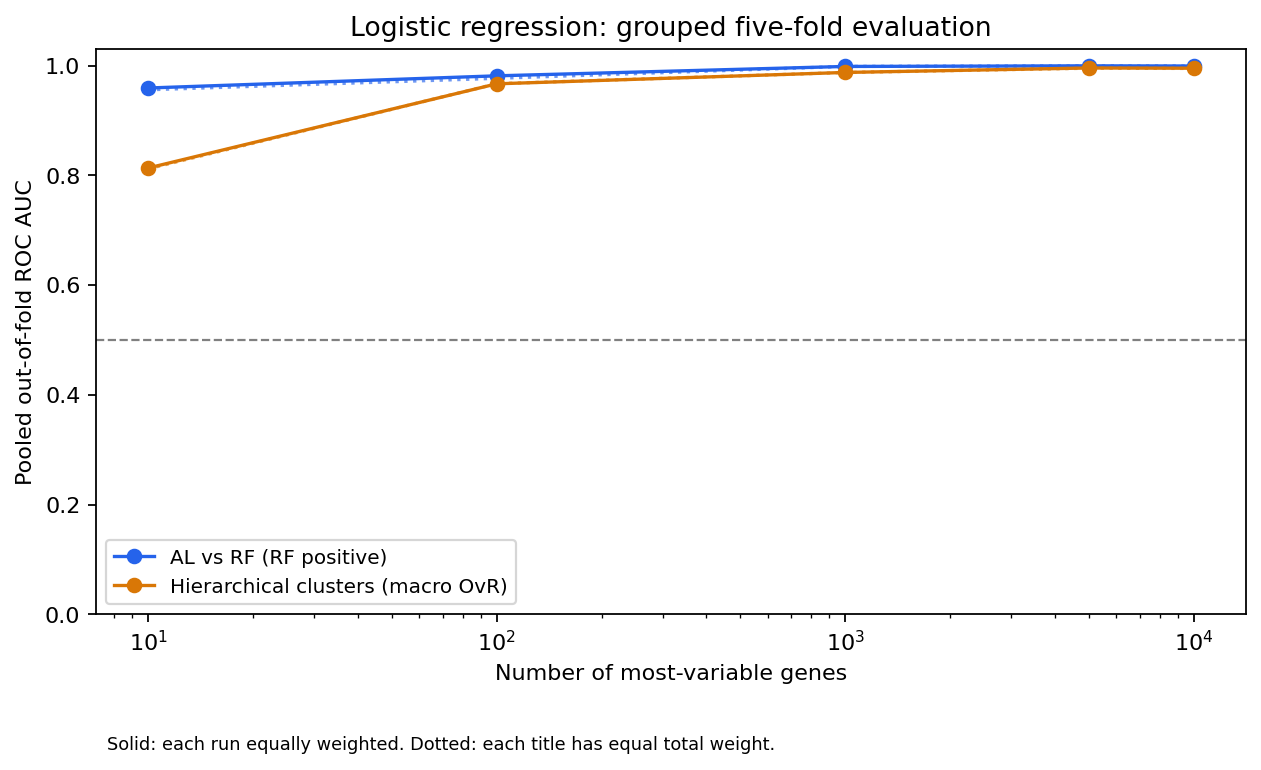

In [18]:
display(Image(filename=str(OUT / "auc_vs_gene_count.png")))


## ROC curves and confusion matrices

ROC curves use held-out scores from the 5,000-gene models.
AL/RF AUC is 0.9995, and average cluster AUC is 0.9956.
Cluster 3 has the lowest individual AUC, at 0.9944.

The confusion matrices compare the true and predicted labels at 5,000 genes.
The feeding model makes nine errors, all AL runs predicted as RF.
The cluster model makes 12 errors, all between clusters 2 and 3.


,target,positive_class,auc
12,feeding_group,RF,0.9995
13,hierarchical_cluster,1,0.9956
14,hierarchical_cluster,2,0.9968
15,hierarchical_cluster,3,0.9944


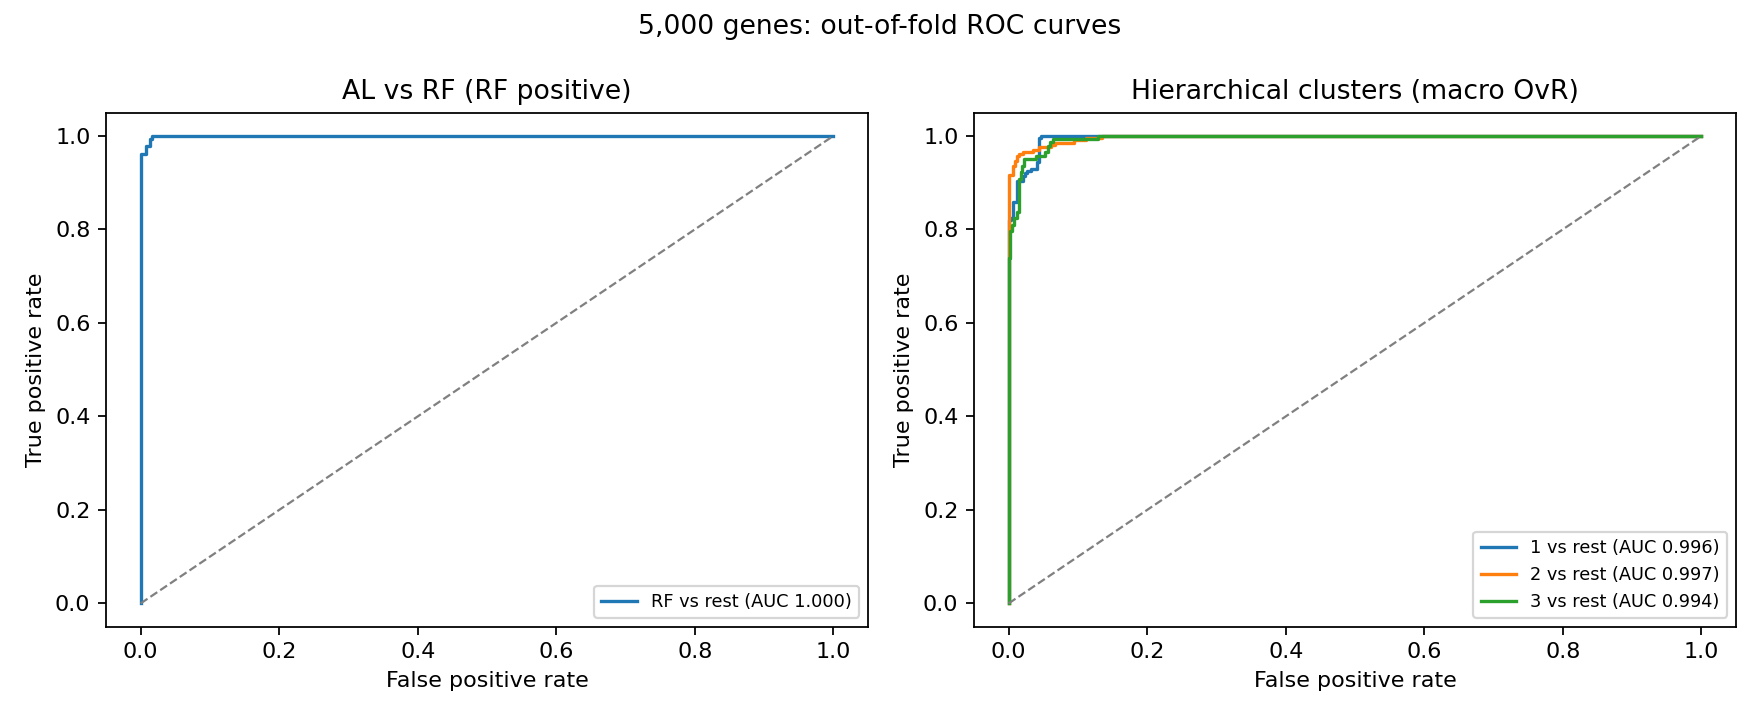

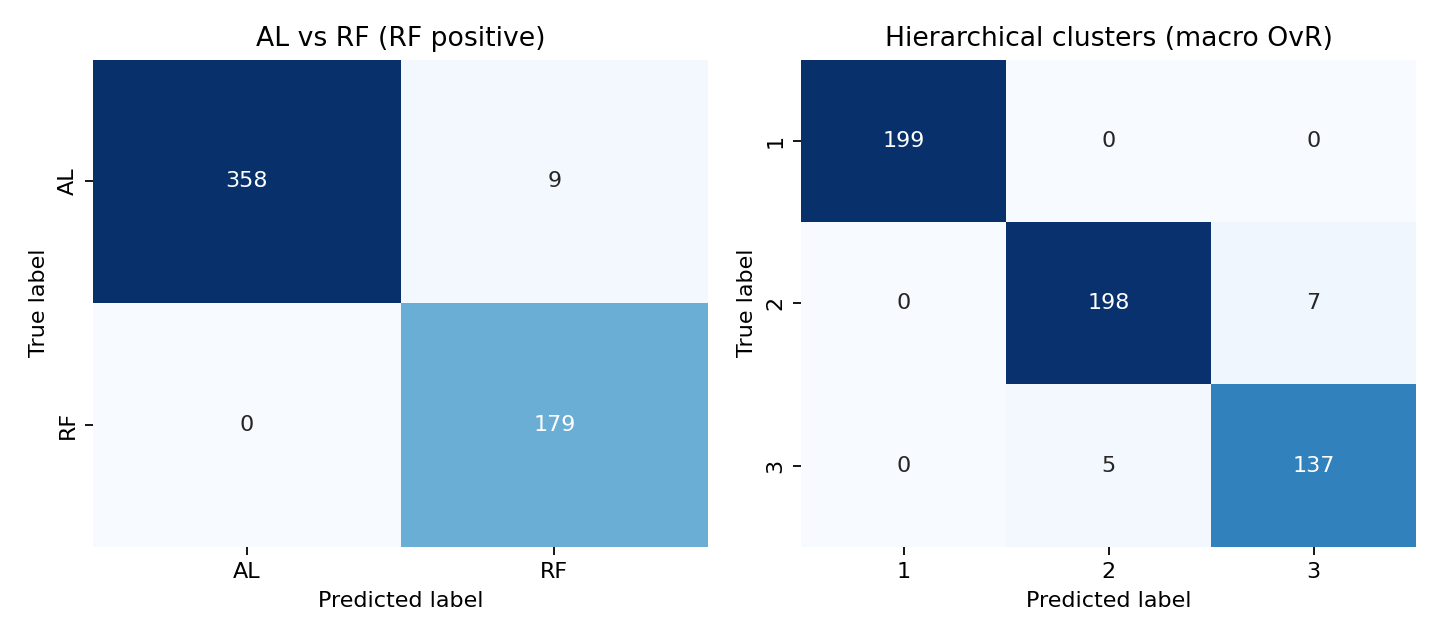

In [19]:
display(results["auc_by_class"].query("n_genes == 5000")[["target", "positive_class", "auc"]].round(4))
display(Image(filename=str(OUT / "roc_5000_genes.png")))
display(Image(filename=str(OUT / "confusion_5000_genes.png")))


## Heatmap

The 5,000-gene models selected 327 gene rows with nonzero coefficients after fitting the full dataset.
This view shows the 30 rows with the largest absolute coefficients.
Colors show standardized expression, and the top bar marks AL/RF.
Both dendrograms use average linkage and Euclidean distance on the genes shown; the full heatmap is linked below.


,gene_symbol,max_abs_coefficient
59,Cpox,0.879854
187,Abhd2,0.869409
241,Ide,0.806601
246,Sdhc,0.767518
305,Scarna2,0.657782
270,mt-Nd6,0.583279
36,Hnrnpab,0.560999
194,Pnrc1,0.534424
223,2900026A02Rik,0.472785
34,Actr2,0.446987


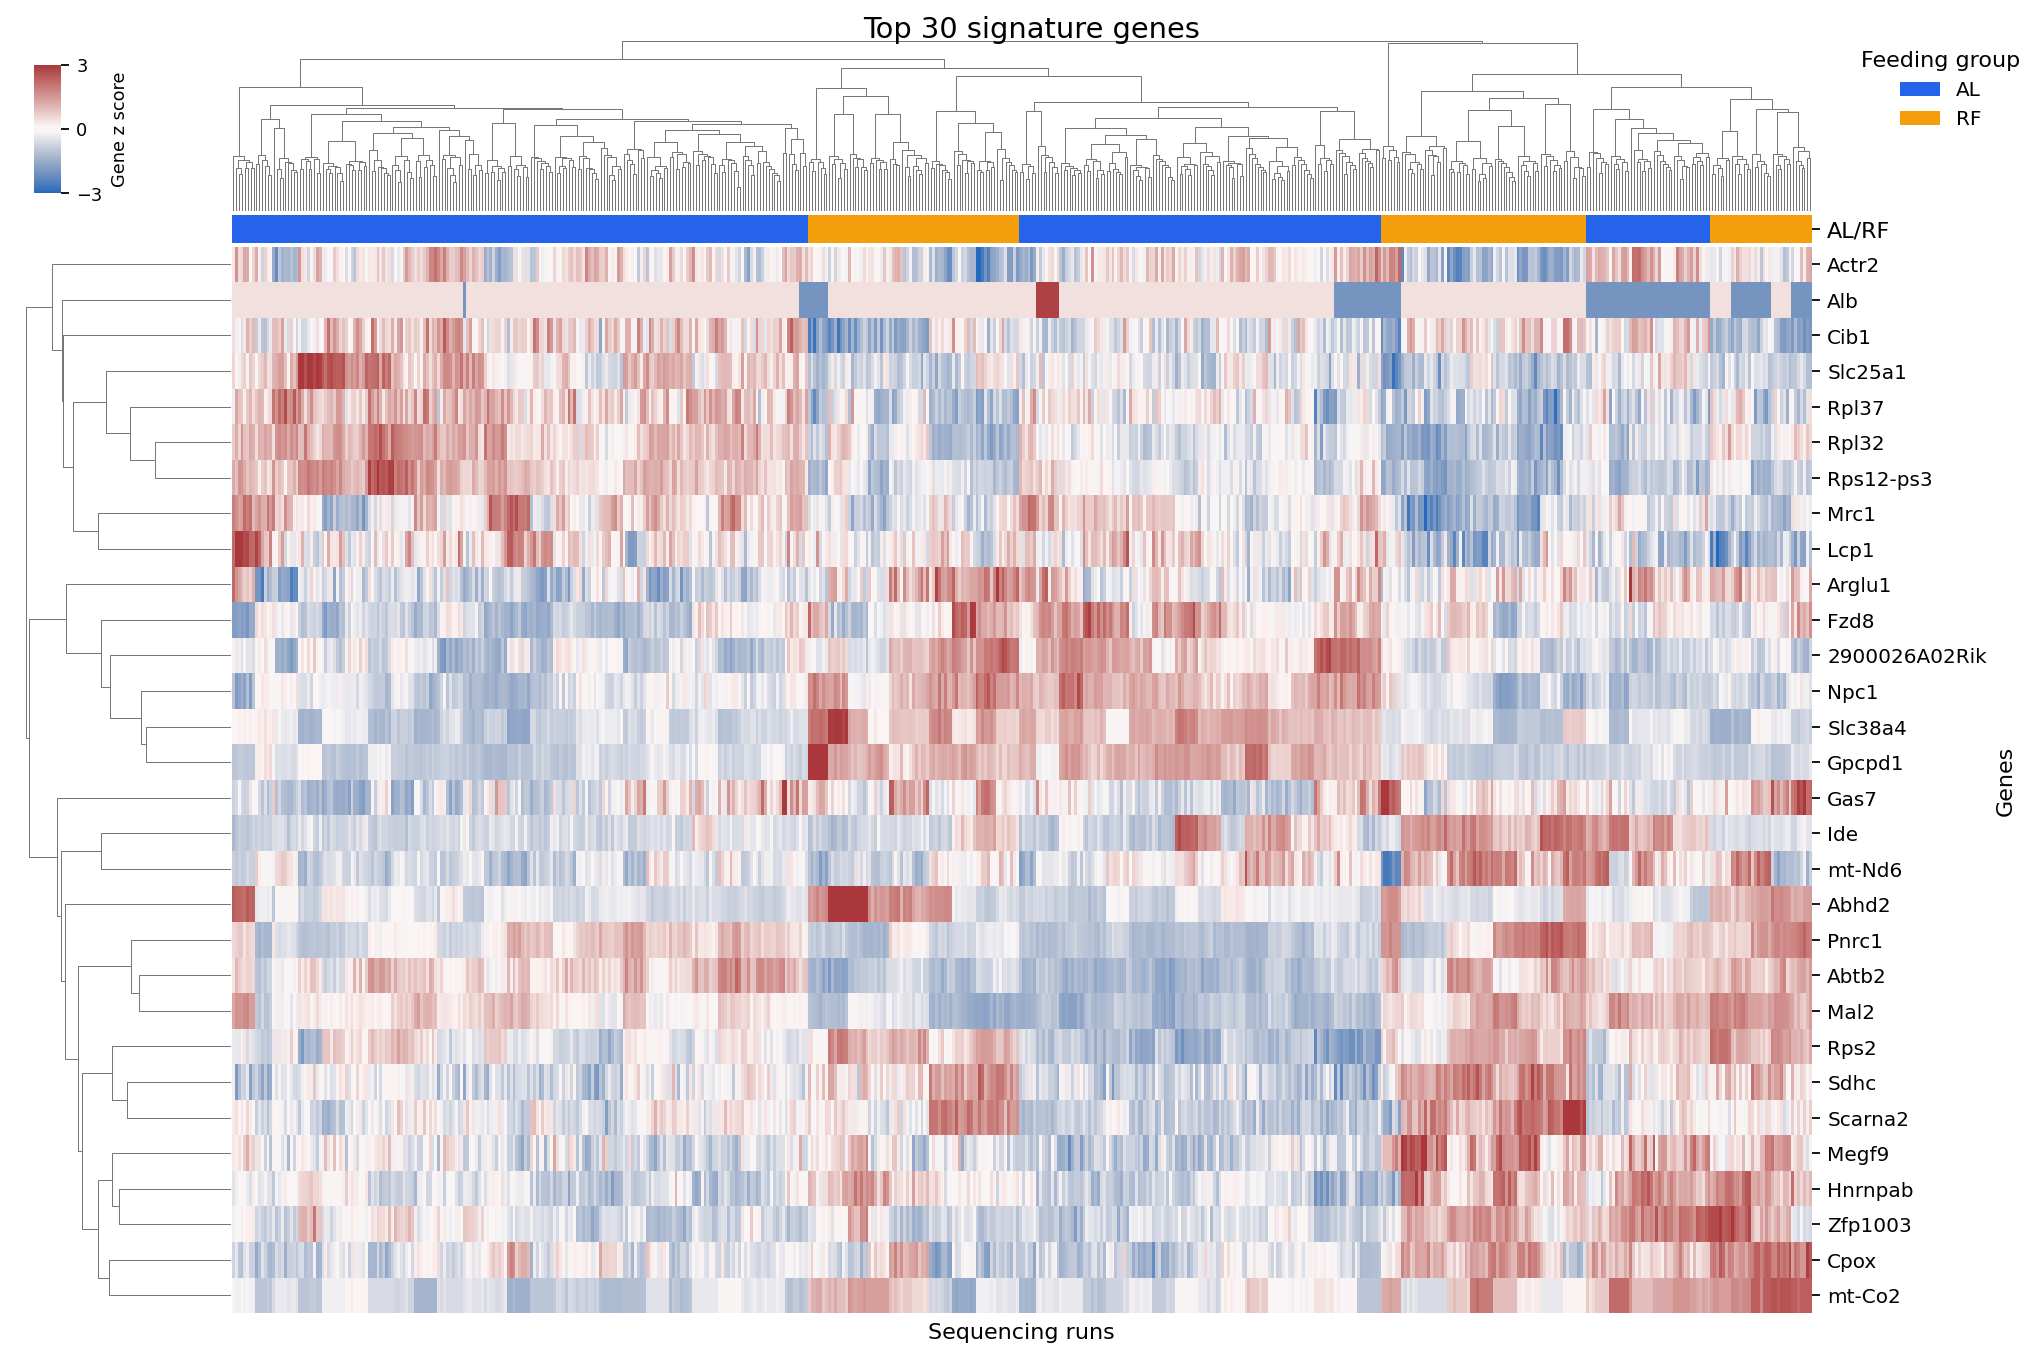

[Open complete heatmap](results/assignment4/logistic_regression/signature_heatmap_all.png)

In [20]:
display(union[["gene_symbol", "max_abs_coefficient"]].head(10))
display(Image(filename=str(OUT / "signature_heatmap_top30.png")))
display(Markdown("[Open complete heatmap](results/assignment4/logistic_regression/signature_heatmap_all.png)"))


## Save the summary

Tables and figures are saved in results/assignment4/logistic_regression.


In [21]:
def write_summary(data, results, union, out=OUT):
    out = Path(out)
    scores = results["metrics"].pivot(index="n_genes", columns="target", values="auc")
    lines = [
        "# Assignment 4 logistic regression", "",
        "L1 logistic regression (C=1, balanced class weights) predicts AL/RF and the three "
        "hierarchical clusters from selected_clusters.csv.", "",
        "Five-fold cross-validation keeps runs with the same title together. "
        "Gene selection and scaling use training data only.", "",
        "| Genes | AL/RF AUC | Cluster AUC (macro OvR) |",
        "|---:|---:|---:|",
    ]
    for n, row in scores.iterrows():
        lines.append("| %s | %.4f | %.4f |" %
                     (n, row["feeding_group"], row["hierarchical_cluster"]))
    lines += [
        "", "Scores use held-out predictions. Cluster AUC measures how well the model "
        "recovers the Assignment 3 labels.", "",
        "Both tasks improve up to 5,000 genes; 10,000 genes gives no further improvement.", "",
        "Plots and short explanations are in "
        "[assignment4_logistic.ipynb](../../../assignment4_logistic.ipynb). "
        "Detailed scores and predictions are saved in metrics.csv and predictions.csv.", "",
        "To rerun, open the notebook from the project folder and choose Run All.", "",
    ]
    (out / "README.md").write_text("\n".join(lines), encoding="utf-8")


In [22]:
write_summary(data, results, union)
